# Notebook 02 — Red neuronal siamesa con Triplet Loss (TensorFlow + Keras)

**Curso:** Deep Learning – Conceptos · Especialización en Inteligencia Artificial · Universidad de Cundinamarca  
**Actividad:** R2-A1-S10 Redes Neuronales V (semana 10: reconocimiento de rostros)  
**Autor:** Juan Pablo Cristancho Tula

Una **red siamesa** tiene dos o tres ramas idénticas que comparten exactamente los mismos pesos. Cada rama convierte
un rostro en un vector de 128 números, al que se le llama *embedding*, y la decisión se toma midiendo la
**distancia** entre esos vectores. Lo interesante es que la red no aprende "quién es cada persona", sino **a medir
parecido**: las caras de una misma persona deben quedar cerca y las de personas distintas, lejos. Gracias a eso puede
reconocer a gente que nunca vio durante el entrenamiento, que es justo lo que necesito para probarla con mis fotos.

Lo que hago en este notebook:

1. Preparo el conjunto público **LFW** (Labeled Faces in the Wild) con el mismo preprocesamiento del Notebook 01.
2. Lo divido **por personas**: quienes quedan en validación y prueba nunca aparecen en el entrenamiento.
3. Construyo el codificador (MobileNetV2 preentrenada más una capa que proyecta a 128 dimensiones con norma 1) y la
   red siamesa de verificación.
4. Implemento **Triplet Loss** con selección de tripletas en línea (semi-difícil y batch-hard) y compruebo que mi
   implementación da lo mismo que un cálculo hecho a mano.
5. Entreno en dos fases y evalúo la verificación facial (ROC, AUC y EER) frente a una línea base sin entrenar.

> Este notebook necesita GPU: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-V/blob/main/notebooks/02_red_siamesa_triplet_loss.ipynb)

In [1]:
# ============================================================
# 0. Configuración
# ============================================================
import os
CONFIG = {
    "USAR_DRIVE": True,
    "CARPETA_BASE": "/content/drive/MyDrive/Redes_Neuronales_V",
    "REPO_URL": "https://github.com/Juanpatula2361/Taller-Redes-Neuronales-V.git",
    "SEMILLA": 42,
    "TAM": 160, "MARGEN_RECORTE": 0.25,
    "MIN_FOTOS_LFW": 6,       # identidades de LFW con al menos 6 fotos (unas 300 personas)
    "MAX_FOTOS_LFW": 30,      # tope por identidad para no desbalancear (p. ej. G. W. Bush tiene 530)
    "PESOS": "imagenet",      # pesos iniciales de MobileNetV2
    "DIM_EMB": 128,           # dimensión del embedding
    "MARGEN_TRIPLETE": 0.3,   # margen alfa de Triplet Loss
    "P": 16, "K": 4,          # lote = P identidades x K imágenes
    "EPOCAS_1": 10, "EPOCAS_2": 20, "PASOS": 100, "PASOS_VAL": 20,
    "LR_1": 1e-3, "LR_2": 1e-4, "CAPAS_A_AJUSTAR": 40,
}
BASE = CONFIG["CARPETA_BASE"]
RES = os.path.join(BASE, "results")
CACHE = os.path.join(BASE, "cache")
MODELOS = os.path.join(BASE, "modelos")
CARPETAS = [RES, CACHE, MODELOS]

In [2]:
# ============================================================
# Configuración del entorno: Drive, dependencias y módulo de preprocesamiento
# ============================================================
import sys, json, time, subprocess, warnings
warnings.filterwarnings("ignore")
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB and CONFIG["USAR_DRIVE"]:
    from google.colab import drive
    drive.mount("/content/drive")

if EN_COLAB:
    # MTCNN (detector facial) y lectores de HEIC (iPhone) y DNG (RAW)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mtcnn==1.0.0", "pillow-heif", "rawpy"], check=True)
    if not os.path.isdir("/content/Taller-Redes-Neuronales-V"):
        subprocess.run(["git", "clone", "-q", CONFIG["REPO_URL"], "/content/Taller-Redes-Neuronales-V"])

# El código de preprocesamiento está en scripts/preprocesamiento_facial.py (un solo origen para los 3 notebooks)
for ruta in ["/content/Taller-Redes-Neuronales-V/scripts", os.path.join(BASE, "scripts"),
             os.path.abspath("../scripts"), os.path.abspath("scripts")]:
    if os.path.isfile(os.path.join(ruta, "preprocesamiento_facial.py")):
        sys.path.insert(0, ruta)
        break
else:
    raise FileNotFoundError("No se encontró scripts/preprocesamiento_facial.py: suba el repositorio a GitHub "
                            "o copie la carpeta scripts/ dentro de CARPETA_BASE.")
import preprocesamiento_facial as pf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
for carpeta in CARPETAS:
    os.makedirs(carpeta, exist_ok=True)
print("Colab:", EN_COLAB, "| carpeta base:", BASE)

import tensorflow as tf
import keras
from keras import layers
keras.utils.set_random_seed(CONFIG["SEMILLA"])
rng = np.random.default_rng(CONFIG["SEMILLA"])
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Mounted at /content/drive
Colab: True | carpeta base: /content/drive/MyDrive/Redes_Neuronales_V
TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset de entrenamiento: LFW

Con mis fotos no alcanza para entrenar una red: para aprender a distinguir rostros se necesitan miles de imágenes de
cientos de personas. Por eso entreno con **Labeled Faces in the Wild** (Huang et al., 2007), un conjunto público con
13.233 fotografías de 5.749 personas tomadas en condiciones reales, que es la referencia clásica en verificación
facial y se puede usar libremente con fines académicos. Mis fotos quedan reservadas para la etapa de prueba.

Tomo las personas que tienen al menos 6 fotos, con un máximo de 30 por persona para que ninguna domine el
entrenamiento, y paso cada imagen por **el mismo** preprocesamiento del Notebook 01 (MTCNN, alineación y recorte de
160 × 160). Como este paso tarda varios minutos, guardo el resultado en Drive y en las siguientes ejecuciones lo cargo
directamente.

Una lección de la primera ejecución: al descomprimir LFW directamente en Google Drive, Drive solo listó una parte de
las 5.749 carpetas y el modelo terminó entrenando con apenas 16 personas, así que memorizó a esas personas en lugar de
aprender a comparar rostros. Por eso ahora descargo LFW en el disco local de Colab, guardo en Drive únicamente el
resultado ya preprocesado y verifico que el conjunto esté completo antes de seguir.

In [3]:
# ============================================================
# 1. Descarga, selección y preprocesamiento de LFW (con caché)
# ============================================================
NOMBRE_CACHE = f"lfw_alineado_{CONFIG['TAM']}_min{CONFIG['MIN_FOTOS_LFW']}_max{CONFIG['MAX_FOTOS_LFW']}.npz"
ruta_cache = os.path.join(CACHE, NOMBRE_CACHE)
if os.path.exists(ruta_cache):
    datos = np.load(ruta_cache, allow_pickle=True)
    X_lfw, y_lfw, nombres_lfw = datos["X"], datos["y"], list(datos["nombres"])
    n_alternativo = int(datos["n_alternativo"])
    print("LFW cargado desde caché:", ruta_cache)
else:
    from sklearn.datasets._lfw import _check_fetch_lfw
    # LFW se descarga y descomprime en el disco local de Colab, NO en Drive: Google Drive no lista de forma
    # confiable carpetas con miles de subcarpetas y el conjunto quedaría incompleto. Solo el resultado
    # preprocesado (un único archivo .npz) se guarda en Drive.
    datos_sklearn = "/content/scikit_learn_data" if EN_COLAB else os.path.join(CACHE, "sklearn")
    _, carpeta_lfw = _check_fetch_lfw(data_home=datos_sklearn, funneled=True, download_if_missing=True)
    todas = [p for p in os.listdir(carpeta_lfw) if os.path.isdir(os.path.join(carpeta_lfw, p))]
    n_total = sum(len(os.listdir(os.path.join(carpeta_lfw, p))) for p in todas)
    print(f"LFW descargado: {len(todas)} personas y {n_total} fotos en {carpeta_lfw}")
    assert len(todas) > 5000 and n_total > 13000, (
        "LFW quedó incompleto (deberían ser 5.749 personas y 13.233 fotos). Borre la carpeta "
        f"{datos_sklearn} y vuelva a ejecutar esta celda.")
    seleccion = []
    for persona in sorted(os.listdir(carpeta_lfw)):
        d = os.path.join(carpeta_lfw, persona)
        if os.path.isdir(d):
            fotos = sorted(os.listdir(d))
            if len(fotos) >= CONFIG["MIN_FOTOS_LFW"]:
                if len(fotos) > CONFIG["MAX_FOTOS_LFW"]:
                    fotos = sorted(rng.choice(fotos, CONFIG["MAX_FOTOS_LFW"], replace=False))
                seleccion.append((persona, [os.path.join(d, f) for f in fotos]))
    detector = pf.crear_detector()
    X_lfw, y_lfw, nombres_lfw, n_alternativo = [], [], [], 0
    t0 = time.perf_counter()
    for i, (persona, rutas) in enumerate(seleccion):
        nombres_lfw.append(persona)
        for r in rutas:
            img = cv2.cvtColor(cv2.imread(r), cv2.COLOR_BGR2RGB)
            res = pf.procesar_imagen(img, detector, tam=CONFIG["TAM"], margen=CONFIG["MARGEN_RECORTE"],
                                     criterio="centro", escalas=(1.0, 1.5))
            if res is None:            # sin detección: recorte central (LFW ya viene centrado)
                recorte = pf.recorte_central(img, CONFIG["TAM"]); n_alternativo += 1
            else:
                recorte = res.recorte
            X_lfw.append(recorte); y_lfw.append(i)
        if (i + 1) % 20 == 0:
            print(f"  {i + 1}/{len(seleccion)} identidades ({time.perf_counter() - t0:.0f} s)")
    X_lfw, y_lfw = np.stack(X_lfw).astype(np.uint8), np.array(y_lfw)
    np.savez_compressed(ruta_cache, X=X_lfw, y=y_lfw, nombres=np.array(nombres_lfw), n_alternativo=n_alternativo)
print(f"LFW: {len(X_lfw)} imágenes, {len(nombres_lfw)} identidades, {n_alternativo} sin detección (recorte central)")

LFW descargado: 5749 personas y 13233 fotos en /content/scikit_learn_data/lfw_home/lfw_funneled


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


  20/311 identidades (62 s)
  40/311 identidades (104 s)
  60/311 identidades (142 s)
  80/311 identidades (181 s)
  100/311 identidades (231 s)
  120/311 identidades (277 s)
  140/311 identidades (326 s)
  160/311 identidades (372 s)
  180/311 identidades (414 s)
  200/311 identidades (455 s)
  220/311 identidades (494 s)
  240/311 identidades (535 s)
  260/311 identidades (570 s)
  280/311 identidades (608 s)
  300/311 identidades (656 s)
LFW: 4075 imágenes, 311 identidades, 0 sin detección (recorte central)


,conjunto,identidades,imagenes
0,entrenamiento,217,2831
1,validación,46,609
2,prueba,48,635


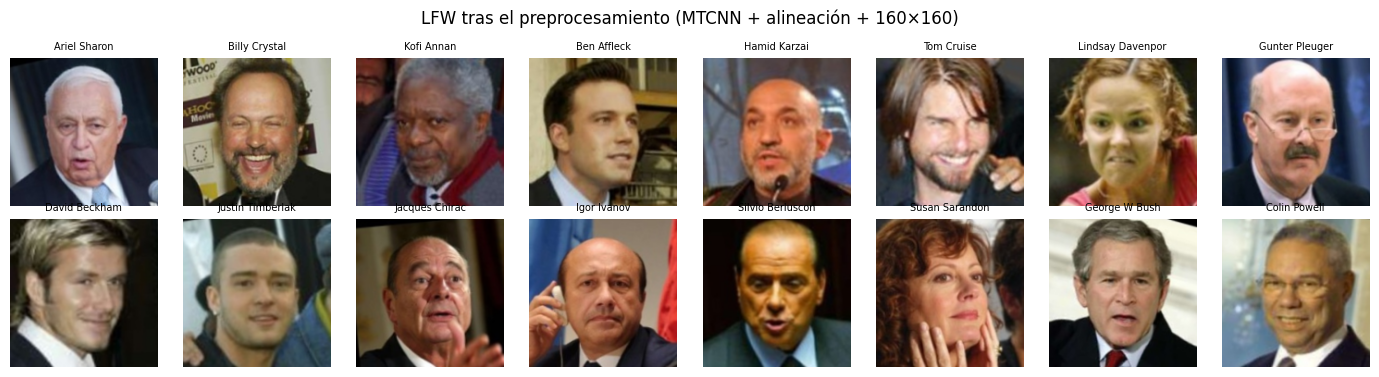

In [4]:
# ============================================================
# 1b. División por identidades (70 % / 15 % / 15 %)
# ============================================================
ids = rng.permutation(np.unique(y_lfw))
n_tr, n_va = int(0.70 * len(ids)), int(0.15 * len(ids))
ids_tr, ids_va, ids_te = ids[:n_tr], ids[n_tr:n_tr + n_va], ids[n_tr + n_va:]

def subconjunto(ids_sel):
    m = np.isin(y_lfw, ids_sel)
    return X_lfw[m], y_lfw[m]

X_tr, y_tr = subconjunto(ids_tr)
X_va, y_va = subconjunto(ids_va)
X_te, y_te = subconjunto(ids_te)
division = pd.DataFrame({
    "conjunto": ["entrenamiento", "validación", "prueba"],
    "identidades": [len(ids_tr), len(ids_va), len(ids_te)],
    "imagenes": [len(X_tr), len(X_va), len(X_te)],
})
display(division)
assert not (set(ids_tr) & set(ids_te)) and not (set(ids_tr) & set(ids_va)), "Las identidades no deben repetirse"

fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for ax, k in zip(axes.ravel(), rng.choice(len(X_tr), 16, replace=False)):
    ax.imshow(X_tr[k]); ax.set_title(nombres_lfw[y_tr[k]].replace("_", " ")[:16], fontsize=7); ax.axis("off")
plt.suptitle("LFW tras el preprocesamiento (MTCNN + alineación + 160×160)")
plt.tight_layout(); plt.savefig(f"{RES}/02_muestras_lfw.png", dpi=120); plt.show()

## 2. Arquitectura

El **codificador** $f_\theta$ es la "rama" de la red siamesa; todas las ramas usan los mismos pesos:

| Capa | Salida | Para qué sirve |
|---|---|---|
| Entrada RGB | 160 × 160 × 3 | el rostro ya alineado |
| `Rescaling` | 160 × 160 × 3 | lleva los píxeles a $[-1, 1]$, el formato que espera MobileNetV2 |
| MobileNetV2 (ImageNet, sin la cabeza de clasificación) + promedio global | 1.280 | extrae rasgos visuales; aprovecho lo que ya aprendió con millones de imágenes (aprendizaje por transferencia) |
| `Dropout(0.2)` | 1.280 | reduce el sobreajuste |
| `Dense(128)` | 128 | proyecta los rasgos al espacio de embeddings |
| `UnitNormalization` | 128 | normaliza el vector para que $\lVert f(x) \rVert_2 = 1$ |

Elegí MobileNetV2 porque es liviana, entrena rápido en la GPU gratuita de Colab y aun así da buenos rasgos visuales.
Al normalizar el embedding, todos los vectores quedan sobre una esfera y la distancia entre dos rostros siempre está
entre 0 y 2, lo que facilita fijar un umbral.

La **red siamesa de verificación** recibe dos rostros $A$ y $B$, los pasa por el **mismo** codificador y calcula
$d(A, B) = \lVert f(A) - f(B) \rVert_2$. Si $d < \tau$ (el umbral), concluye que es la misma persona. Durante el
entrenamiento con tripletas la idea es la misma, solo que con tres ramas: ancla, positivo y negativo.

In [5]:
# ============================================================
# 2. Codificador facial y red siamesa
# ============================================================
TAM = CONFIG["TAM"]

def construir_codificador(pesos=CONFIG["PESOS"], dim=CONFIG["DIM_EMB"]):
    """Codificador: rostro 160x160x3 (0-255) -> embedding de `dim` dimensiones con norma 1."""
    base = keras.applications.MobileNetV2(input_shape=(TAM, TAM, 3), include_top=False,
                                          weights=pesos, pooling="avg")
    base.trainable = False                       # fase 1: solo se entrena la cabeza
    entrada = keras.Input((TAM, TAM, 3), name="rostro")
    x = layers.Rescaling(1 / 127.5, offset=-1, name="escala_mobilenet")(entrada)
    x = base(x, training=False)                  # BatchNorm siempre en modo inferencia
    x = layers.Dropout(0.2, name="dropout")(x)
    x = layers.Dense(dim, name="proyeccion")(x)
    salida = layers.UnitNormalization(name="embedding_l2")(x)
    return keras.Model(entrada, salida, name="codificador_facial"), base


@keras.saving.register_keras_serializable(package="rn5")
class DistanciaEuclidea(layers.Layer):
    """Distancia L2 entre dos lotes de embeddings."""
    def call(self, a, b):
        return keras.ops.sqrt(keras.ops.sum(keras.ops.square(a - b), axis=-1, keepdims=True) + 1e-12)


def construir_siamesa(codificador):
    """Red siamesa: dos rostros -> mismo codificador (pesos compartidos) -> distancia."""
    a = keras.Input((TAM, TAM, 3), name="rostro_A")
    b = keras.Input((TAM, TAM, 3), name="rostro_B")
    d = DistanciaEuclidea(name="distancia_L2")(codificador(a), codificador(b))
    return keras.Model([a, b], d, name="red_siamesa")


codificador, base = construir_codificador()
siamesa = construir_siamesa(codificador)
codificador.summary()
siamesa.summary()
print("Capas de MobileNetV2:", len(base.layers))
try:
    keras.utils.plot_model(siamesa, to_file=f"{RES}/02_arquitectura_siamesa.png", show_shapes=True,
                           expand_nested=False, dpi=110)
except Exception as e:
    print("plot_model no disponible:", e)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "codificador_facial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rostro (InputLayer)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escala_mobilenet (Rescaling)    │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ proyeccion (Dense)              │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_l2                    │ (None, 128)            │             0 │
│ (UnitNormalization)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,421,952 (9.24 MB)

 Trainable params: 163,968 (640.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

... (2 outputs left out)

 Total params: 2,421,952 (9.24 MB)

 Trainable params: 163,968 (640.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Capas de MobileNetV2: 155


## 3. Triplet Loss

La pérdida trabaja con tripletas: un **ancla** $a$, un **positivo** $p$ (otra foto de la misma persona) y un
**negativo** $n$ (una foto de otra persona):

$$\mathcal{L}(a, p, n) = \max\big(0,\; \lVert f(a) - f(p) \rVert_2 - \lVert f(a) - f(n) \rVert_2 + \alpha\big)$$

Dicho en palabras: la pérdida vale cero cuando el negativo queda al menos $\alpha$ más lejos del ancla que el positivo
(Schroff et al., 2015). El detalle práctico es que la mayoría de tripletas elegidas al azar ya cumplen esa condición y
no le enseñan nada a la red, por eso las tripletas se **eligen dentro de cada lote** de $P$ personas × $K$ fotos:

- **Semi-difícil (semi-hard)**, la estrategia de FaceNet, que es la que uso para entrenar: para cada par
  ancla-positivo busco el negativo más cercano que todavía esté **más lejos** que el positivo
  ($d_{ap} < d_{an} < d_{ap} + \alpha$); si no existe, tomo el negativo más lejano. Así la red recibe ejemplos
  retadores pero no imposibles. Usar solo las tripletas más difíciles desde el comienzo puede hacer que todos los
  embeddings colapsen en un mismo punto (Schroff et al., 2015).
- **Batch-hard** (Hermans et al., 2017): para cada ancla, el positivo más lejano y el negativo más cercano. La
  implemento y la verifico como punto de comparación.

In [6]:
# ============================================================
# 3. Implementación de Triplet Loss (básica y batch-hard)
# ============================================================
def triplet_loss_basica(ancla, positivo, negativo, margen=CONFIG["MARGEN_TRIPLETE"]):
    """Ecuación de Triplet Loss para tripletas explícitas (embeddings de forma [N, d])."""
    d_ap = tf.norm(ancla - positivo, axis=1)
    d_an = tf.norm(ancla - negativo, axis=1)
    return tf.reduce_mean(tf.maximum(d_ap - d_an + margen, 0.0))


def distancias_por_pares(emb):
    """Matriz D[i, j] = ||e_i - e_j||_2 calculada de forma vectorizada."""
    sq = tf.reduce_sum(tf.square(emb), axis=1, keepdims=True)
    d2 = tf.maximum(sq - 2.0 * tf.matmul(emb, emb, transpose_b=True) + tf.transpose(sq), 0.0)
    return tf.sqrt(d2 + 1e-12)


def tripletas_batch_hard(etiquetas, emb, margen):
    """Pérdida por ancla con el positivo más lejano y el negativo más cercano del lote."""
    etiquetas = tf.reshape(tf.cast(etiquetas, tf.int32), [-1])
    D = distancias_por_pares(emb)
    misma = tf.equal(etiquetas[:, None], etiquetas[None, :])
    diagonal = tf.eye(tf.shape(etiquetas)[0], dtype=tf.bool)
    mascara_pos = tf.logical_and(misma, tf.logical_not(diagonal))
    d_ap = tf.reduce_max(tf.where(mascara_pos, D, tf.zeros_like(D)), axis=1)          # positivo más difícil
    d_an = tf.reduce_min(tf.where(misma, tf.fill(tf.shape(D), 1e9), D), axis=1)        # negativo más difícil
    return tf.maximum(d_ap - d_an + margen, 0.0)


def tripletas_semi_dificiles(etiquetas, emb, margen):
    """Triplet Loss con minado semi-difícil sobre todos los pares ancla-positivo del lote (FaceNet)."""
    etiquetas = tf.reshape(tf.cast(etiquetas, tf.int32), [-1])
    D = distancias_por_pares(emb)
    misma = tf.equal(etiquetas[:, None], etiquetas[None, :])
    diagonal = tf.eye(tf.shape(etiquetas)[0], dtype=tf.bool)
    mascara_pos = tf.logical_and(misma, tf.logical_not(diagonal))        # pares (a, p)
    mascara_neg = tf.logical_not(misma)                                  # pares (a, n)
    d_ap = D[:, :, None]                                                 # [a, p, 1]
    d_an = tf.broadcast_to(D[:, None, :], tf.shape(D)[0] * tf.ones(3, tf.int32))   # [a, p, n]
    semi = tf.logical_and(mascara_neg[:, None, :], d_an > d_ap)          # negativos más lejos que p
    d_semi = tf.reduce_min(tf.where(semi, d_an, tf.fill(tf.shape(d_an), 1e9)), axis=2)
    d_lejano = tf.reduce_max(tf.where(mascara_neg, D, tf.fill(tf.shape(D), -1e9)), axis=1)
    d_neg = tf.where(tf.reduce_any(semi, axis=2), d_semi, d_lejano[:, None])
    perdida = tf.where(mascara_pos, tf.maximum(D - d_neg + margen, 0.0), 0.0)
    n_pares = tf.maximum(tf.reduce_sum(tf.cast(mascara_pos, tf.float32)), 1.0)
    return perdida, mascara_pos, n_pares


@keras.saving.register_keras_serializable(package="rn5")
class TripletLossSemiDificil(keras.losses.Loss):
    """Pérdida usada en el entrenamiento: promedio sobre todos los pares ancla-positivo del lote."""
    def __init__(self, margen=0.3, name="triplet_semi_dificil", **kwargs):
        super().__init__(name=name, **kwargs)
        self.margen = margen

    def call(self, y_true, y_pred):
        perdida, _, n = tripletas_semi_dificiles(y_true, y_pred, self.margen)
        return tf.reduce_sum(perdida) / n

    def get_config(self):
        return {**super().get_config(), "margen": self.margen}


def fraccion_activa(y_true, y_pred):
    """Proporción de pares ancla-positivo cuya tripleta todavía viola el margen (aportan gradiente)."""
    perdida, pos, n = tripletas_semi_dificiles(y_true, y_pred, CONFIG["MARGEN_TRIPLETE"])
    return tf.reduce_sum(tf.cast(tf.logical_and(pos, perdida > 0), tf.float32)) / n


# Verificación: las versiones vectorizadas coinciden con un cálculo por fuerza bruta en NumPy
e = rng.normal(size=(12, 8)).astype("float32"); e /= np.linalg.norm(e, axis=1, keepdims=True)
lab = np.repeat(np.arange(4), 3)
dist = lambda i, j: np.linalg.norm(e[i] - e[j])
ref_bh, ref_sh = [], []
for a in range(len(e)):
    pos = [p for p in range(len(e)) if lab[p] == lab[a] and p != a]
    neg = [n for n in range(len(e)) if lab[n] != lab[a]]
    ref_bh.append(max(max(dist(a, p) for p in pos) - min(dist(a, n) for n in neg) + 0.3, 0.0))
    for p in pos:
        semi = [dist(a, n) for n in neg if dist(a, n) > dist(a, p)]
        dn = min(semi) if semi else max(dist(a, n) for n in neg)
        ref_sh.append(max(dist(a, p) - dn + 0.3, 0.0))
dif_bh = np.abs(np.array(ref_bh) - tripletas_batch_hard(lab, tf.constant(e), 0.3).numpy()).max()
dif_sh = abs(np.mean(ref_sh) - float(TripletLossSemiDificil(0.3)(lab, tf.constant(e))))
print(f"Diferencia máxima batch-hard vs. fuerza bruta:   {dif_bh:.2e}")
print(f"Diferencia semi-difícil vs. fuerza bruta (media): {dif_sh:.2e}")
print("Ejemplo con tripletas explícitas:", float(triplet_loss_basica(tf.constant(e[[0, 3]]), tf.constant(e[[1, 4]]), tf.constant(e[[6, 9]]))))
assert dif_bh < 1e-4 and dif_sh < 1e-4

Diferencia máxima batch-hard vs. fuerza bruta:   1.19e-07
Diferencia semi-difícil vs. fuerza bruta (media): 2.98e-08
Ejemplo con tripletas explícitas: 0.8089361190795898


## 4. Muestreo P × K y aumento de datos

Cada lote tiene $P = 16$ personas con $K = 4$ fotos de cada una, es decir 64 rostros. Esta forma de armar los lotes no
es un capricho: garantiza que cada ancla tenga positivos y negativos dentro del mismo lote para poder formar
tripletas. Además aplico aumento de datos (volteo horizontal, pequeñas rotaciones, zoom, desplazamientos y cambios de
brillo y contraste) para simular las variaciones que tienen las fotos reales de mi dataset.

Lote de entrenamiento: (64, 160, 160, 3) | identidades distintas en el lote: 16


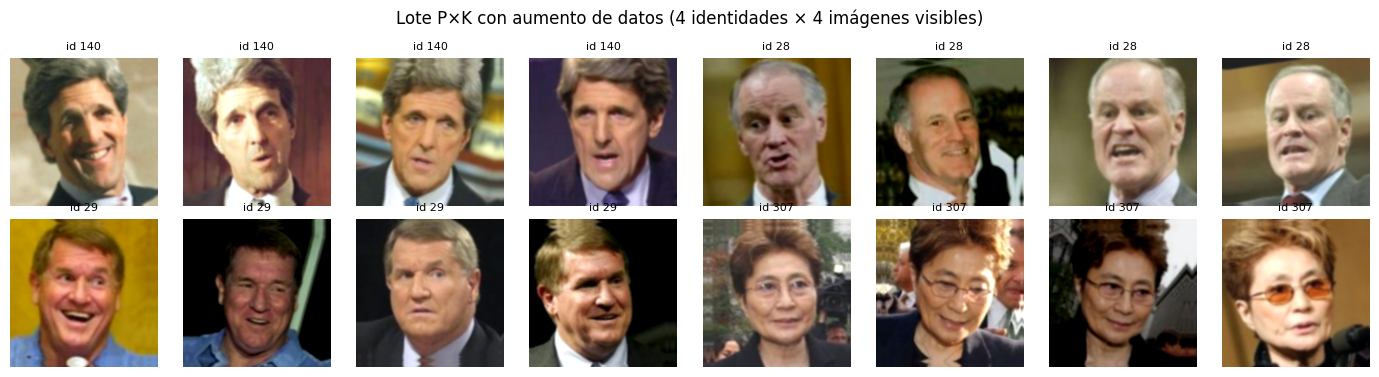

In [7]:
# ============================================================
# 4. Generador P x K y aumento de datos
# ============================================================
AUTOTUNE = tf.data.AUTOTUNE
P, K = CONFIG["P"], CONFIG["K"]
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04, fill_mode="reflect"),
    layers.RandomZoom(0.10, fill_mode="reflect"),
    layers.RandomTranslation(0.05, 0.05, fill_mode="reflect"),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.20),
], name="aumento_datos")


def lotes_pk(X, y, semilla):
    """Generador infinito de lotes con P identidades y K imágenes por identidad."""
    g = np.random.default_rng(semilla)
    por_id = {c: np.flatnonzero(y == c) for c in np.unique(y)}
    ids_validos = np.array([c for c, v in por_id.items() if len(v) >= 2])
    p = min(P, len(ids_validos))                 # por si un conjunto tiene menos de P identidades
    while True:
        elegidos = g.choice(ids_validos, size=p, replace=False)
        idx = np.concatenate([g.choice(por_id[c], size=K, replace=len(por_id[c]) < K) for c in elegidos])
        yield X[idx], y[idx].astype(np.int32)


def crear_dataset(X, y, semilla, aumentar):
    firma = (tf.TensorSpec((None, TAM, TAM, 3), tf.uint8), tf.TensorSpec((None,), tf.int32))
    ds = tf.data.Dataset.from_generator(lambda: lotes_pk(X, y, semilla), output_signature=firma)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    if aumentar:
        ds = ds.map(lambda a, b: (tf.clip_by_value(aumento(a, training=True), 0.0, 255.0), b),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


ds_tr = crear_dataset(X_tr, y_tr, CONFIG["SEMILLA"], aumentar=True)
ds_va = crear_dataset(X_va, y_va, CONFIG["SEMILLA"] + 1, aumentar=False)
xb, yb = next(iter(ds_tr))
print("Lote de entrenamiento:", xb.shape, "| identidades distintas en el lote:", len(np.unique(yb)))
fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for ax, k in zip(axes.ravel(), range(16)):
    ax.imshow(xb[k].numpy().astype("uint8")); ax.set_title(f"id {int(yb[k])}", fontsize=8); ax.axis("off")
plt.suptitle("Lote P×K con aumento de datos (4 identidades × 4 imágenes visibles)")
plt.tight_layout(); plt.savefig(f"{RES}/02_lote_pk_aumento.png", dpi=120); plt.show()

## 5. Herramientas de evaluación y línea base

Para evaluar la verificación armo pares de rostros: todos los pares **genuinos** (misma persona, hasta 200 por
persona) y la misma cantidad de pares **impostores** (personas distintas) elegidos al azar.

Como punto de referencia uso una **línea base**: los rasgos de MobileNetV2 preentrenada en ImageNet, tal cual, **sin**
entrenar con Triplet Loss. Comparar contra ella me permite medir cuánto aporta realmente aprender la métrica, y no
atribuirle al entrenamiento lo que ya traía el modelo preentrenado.

In [8]:
# ============================================================
# 5. Pares de evaluación, métricas y línea base
# ============================================================
from sklearn.metrics import roc_auc_score, roc_curve

def construir_pares(y, semilla, max_pos_por_id=200):
    g = np.random.default_rng(semilla)
    positivos = []
    for c in np.unique(y):
        idx = np.flatnonzero(y == c)
        comb = [(i, j) for a, i in enumerate(idx) for j in idx[a + 1:]]
        if len(comb) > max_pos_por_id:
            comb = [comb[k] for k in g.choice(len(comb), max_pos_por_id, replace=False)]
        positivos += comb
    negativos = set()
    while len(negativos) < len(positivos):
        i, j = g.integers(0, len(y), 2)
        if y[i] != y[j]:
            negativos.add((min(i, j), max(i, j)))
    pares = np.array(positivos + sorted(negativos))
    etiquetas = np.r_[np.ones(len(positivos)), np.zeros(len(negativos))]
    return pares, etiquetas


def embeddings(modelo, X, lote=128):
    return modelo.predict(X.astype("float32"), batch_size=lote, verbose=0)


def distancias_pares(E, pares):
    return np.linalg.norm(E[pares[:, 0]] - E[pares[:, 1]], axis=1)


def mejor_umbral(d, etiquetas):
    """Umbral que maximiza la exactitud de verificación (se elige en validación)."""
    candidatos = np.unique(np.round(d, 4))
    exactitudes = [np.mean((d < t) == etiquetas) for t in candidatos]
    k = int(np.argmax(exactitudes))
    return float(candidatos[k]), float(exactitudes[k])


def metricas_verificacion(d, etiquetas, umbral):
    fpr, tpr, _ = roc_curve(etiquetas, -d)
    eer_idx = int(np.nanargmin(np.abs(fpr - (1 - tpr))))
    return {
        "auc": float(roc_auc_score(etiquetas, -d)),
        "eer": float((fpr[eer_idx] + 1 - tpr[eer_idx]) / 2),
        "exactitud": float(np.mean((d < umbral) == etiquetas)),
        "tar_far_1": float(tpr[fpr <= 0.01].max()) if np.any(fpr <= 0.01) else 0.0,
        "tasa_acept_genuinos": float(np.mean(d[etiquetas == 1] < umbral)),
        "tasa_acept_impostores": float(np.mean(d[etiquetas == 0] < umbral)),
        "dist_media_genuinos": float(d[etiquetas == 1].mean()),
        "dist_media_impostores": float(d[etiquetas == 0].mean()),
    }, (fpr, tpr)


pares_va, lab_va = construir_pares(y_va, 1)
pares_te, lab_te = construir_pares(y_te, 2)
print(f"Pares de validación: {len(pares_va)} | pares de prueba: {len(pares_te)}")

# Línea base: MobileNetV2 (ImageNet) + promedio global + normalización L2, sin Triplet Loss
entrada = keras.Input((TAM, TAM, 3))
x = layers.Rescaling(1 / 127.5, offset=-1)(entrada)
x = keras.applications.MobileNetV2(input_shape=(TAM, TAM, 3), include_top=False, weights=CONFIG["PESOS"],
                                   pooling="avg")(x, training=False)
linea_base = keras.Model(entrada, layers.UnitNormalization()(x), name="linea_base_imagenet")
d_va_b = distancias_pares(embeddings(linea_base, X_va), pares_va)
d_te_b = distancias_pares(embeddings(linea_base, X_te), pares_te)
umbral_b, _ = mejor_umbral(d_va_b, lab_va)
met_base, roc_base = metricas_verificacion(d_te_b, lab_te, umbral_b)
print("Línea base (sin entrenar) en prueba:", {k: round(v, 4) for k, v in met_base.items()})

Pares de validación: 7312 | pares de prueba: 7608
Línea base (sin entrenar) en prueba: {'auc': 0.7435, 'eer': 0.321, 'exactitud': 0.6711, 'tar_far_1': 0.0986, 'tasa_acept_genuinos': 0.5507, 'tasa_acept_impostores': 0.2085, 'dist_media_genuinos': 0.7656, 'dist_media_impostores': 0.8717}


## 6. Entrenamiento en dos fases

- **Fase 1**: congelo MobileNetV2 y entreno solo la proyección final, con tasa de aprendizaje de 1e-3.
- **Fase 2** (*fine-tuning*): descongelo las últimas 40 capas de MobileNetV2 y sigo entrenando con una tasa más baja,
  1e-4. Las capas de BatchNormalization las dejo en modo inferencia para que los lotes pequeños no alteren sus
  estadísticas.

Hacerlo en dos fases evita que, al principio, los gradientes grandes de una capa recién creada dañen los pesos
preentrenados. Durante el entrenamiento sigo la pérdida en las personas de validación y la **fracción de tripletas
activas**, es decir, cuántos pares ancla-positivo todavía no cumplen el margen.

In [9]:
# ============================================================
# 6. Entrenamiento
# ============================================================
perdida = TripletLossSemiDificil(margen=CONFIG["MARGEN_TRIPLETE"])
codificador.compile(optimizer=keras.optimizers.Adam(CONFIG["LR_1"]), loss=perdida, metrics=[fraccion_activa])
t0 = time.perf_counter()
h1 = codificador.fit(ds_tr, steps_per_epoch=CONFIG["PASOS"], validation_data=ds_va,
                     validation_steps=CONFIG["PASOS_VAL"], epochs=CONFIG["EPOCAS_1"], verbose=2)

base.trainable = True
for capa in base.layers[:-CONFIG["CAPAS_A_AJUSTAR"]]:
    capa.trainable = False
for capa in base.layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False
codificador.compile(optimizer=keras.optimizers.Adam(CONFIG["LR_2"]), loss=perdida, metrics=[fraccion_activa])
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
h2 = codificador.fit(ds_tr, steps_per_epoch=CONFIG["PASOS"], validation_data=ds_va,
                     validation_steps=CONFIG["PASOS_VAL"], initial_epoch=CONFIG["EPOCAS_1"],
                     epochs=CONFIG["EPOCAS_1"] + CONFIG["EPOCAS_2"], callbacks=[parada], verbose=2)
tiempo_entrenamiento = time.perf_counter() - t0
historial = {k: h1.history[k] + h2.history.get(k, []) for k in h1.history}
print(f"Tiempo total de entrenamiento: {tiempo_entrenamiento / 60:.1f} min | épocas: {len(historial['loss'])}")

Epoch 1/10
100/100 - 83s - 833ms/step - fraccion_activa: 0.9962 - loss: 0.2719 - val_fraccion_activa: 0.9701 - val_loss: 0.2570
Epoch 2/10
100/100 - 48s - 477ms/step - fraccion_activa: 0.9881 - loss: 0.2544 - val_fraccion_activa: 0.9651 - val_loss: 0.2513
Epoch 3/10
100/100 - 63s - 625ms/step - fraccion_activa: 0.9869 - loss: 0.2500 - val_fraccion_activa: 0.9661 - val_loss: 0.2474
Epoch 4/10
100/100 - 50s - 502ms/step - fraccion_activa: 0.9807 - loss: 0.2446 - val_fraccion_activa: 0.9654 - val_loss: 0.2486
Epoch 5/10
100/100 - 53s - 533ms/step - fraccion_activa: 0.9767 - loss: 0.2426 - val_fraccion_activa: 0.9641 - val_loss: 0.2474
Epoch 6/10
100/100 - 49s - 491ms/step - fraccion_activa: 0.9702 - loss: 0.2363 - val_fraccion_activa: 0.9622 - val_loss: 0.2465
Epoch 7/10
100/100 - 49s - 491ms/step - fraccion_activa: 0.9694 - loss: 0.2364 - val_fraccion_activa: 0.9617 - val_loss: 0.2465
Epoch 8/10
100/100 - 51s - 506ms/step - fraccion_activa: 0.9689 - loss: 0.2328 - val_fraccion_activa: 0.

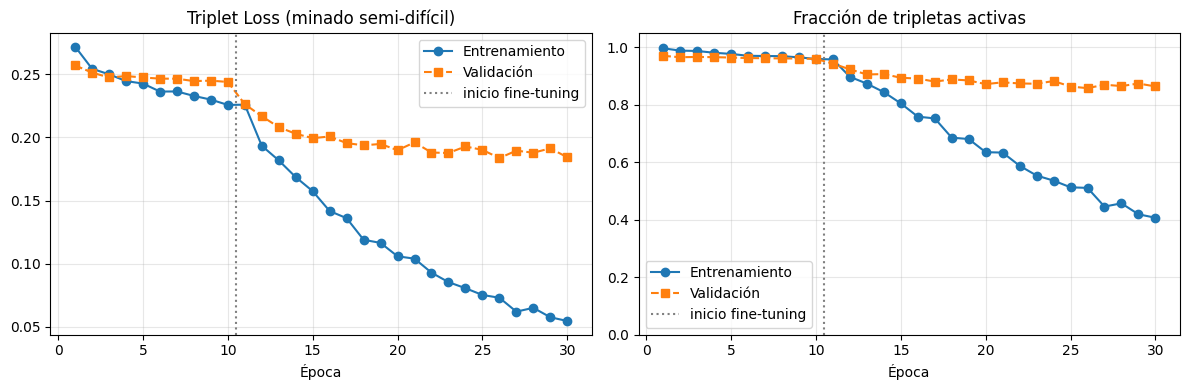

In [10]:
ep = np.arange(1, len(historial["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, historial["loss"], "o-", label="Entrenamiento"); axes[0].plot(ep, historial["val_loss"], "s--", label="Validación")
axes[0].set_title("Triplet Loss (minado semi-difícil)"); axes[0].set_xlabel("Época")
axes[1].plot(ep, historial["fraccion_activa"], "o-", label="Entrenamiento")
axes[1].plot(ep, historial["val_fraccion_activa"], "s--", label="Validación")
axes[1].set_title("Fracción de tripletas activas"); axes[1].set_xlabel("Época"); axes[1].set_ylim(0, 1.05)
for ax in axes:
    ax.axvline(CONFIG["EPOCAS_1"] + 0.5, color="gray", ls=":", label="inicio fine-tuning"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{RES}/02_curvas_entrenamiento.png", dpi=130); plt.show()

## 7. Evaluación de verificación en personas no vistas

El umbral $\tau$ lo elijo con las personas de **validación** y lo aplico tal cual a las de **prueba**, que el modelo
nunca vio; elegirlo directamente sobre la prueba inflaría los resultados. Reporto cuatro métricas:

- **AUC**: el área bajo la curva ROC; 1 es perfecto y 0,5 equivale a lanzar una moneda.
- **EER**: la tasa en la que los falsos rechazos y las falsas aceptaciones se igualan; mientras más baja, mejor.
- **Exactitud** de verificación con el umbral elegido.
- **TAR@FAR = 1 %**: qué porcentaje de pares genuinos acepta el sistema cuando solo se permite aceptar el 1 % de los
  impostores. Es la métrica que más importa si el sistema se usara para dar acceso a algo.

,Línea base (ImageNet),Red siamesa + Triplet Loss
auc,0.7435,0.9177
eer,0.3210,0.1651
exactitud,0.6711,0.8349
tar_far_1,0.0986,0.3449
tasa_acept_genuinos,0.5507,0.8270
tasa_acept_impostores,0.2085,0.1572
dist_media_genuinos,0.7656,0.8427
dist_media_impostores,0.8717,1.3627


Umbral elegido en validación: 1.1214 (exactitud en validación 0.8537)


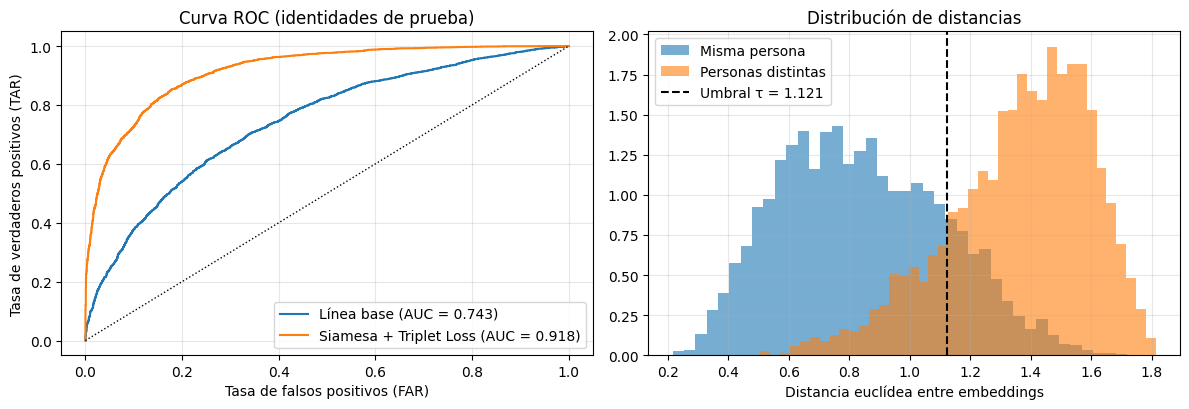

In [11]:
# ============================================================
# 7. Métricas de verificación: modelo entrenado vs. línea base
# ============================================================
E_va, E_te = embeddings(codificador, X_va), embeddings(codificador, X_te)
d_va, d_te = distancias_pares(E_va, pares_va), distancias_pares(E_te, pares_te)
umbral, exact_va = mejor_umbral(d_va, lab_va)
met, roc_mod = metricas_verificacion(d_te, lab_te, umbral)
tabla = pd.DataFrame({"Línea base (ImageNet)": met_base, "Red siamesa + Triplet Loss": met}).round(4)
display(tabla)
print(f"Umbral elegido en validación: {umbral:.4f} (exactitud en validación {exact_va:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(*roc_base, label=f"Línea base (AUC = {met_base['auc']:.3f})")
axes[0].plot(*roc_mod, label=f"Siamesa + Triplet Loss (AUC = {met['auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlabel("Tasa de falsos positivos (FAR)")
axes[0].set_ylabel("Tasa de verdaderos positivos (TAR)"); axes[0].set_title("Curva ROC (identidades de prueba)"); axes[0].legend()
axes[1].hist(d_te[lab_te == 1], bins=40, alpha=.6, label="Misma persona", density=True)
axes[1].hist(d_te[lab_te == 0], bins=40, alpha=.6, label="Personas distintas", density=True)
axes[1].axvline(umbral, color="k", ls="--", label=f"Umbral τ = {umbral:.3f}")
axes[1].set_xlabel("Distancia euclídea entre embeddings"); axes[1].set_title("Distribución de distancias"); axes[1].legend()
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{RES}/02_roc_y_distancias.png", dpi=130); plt.show()

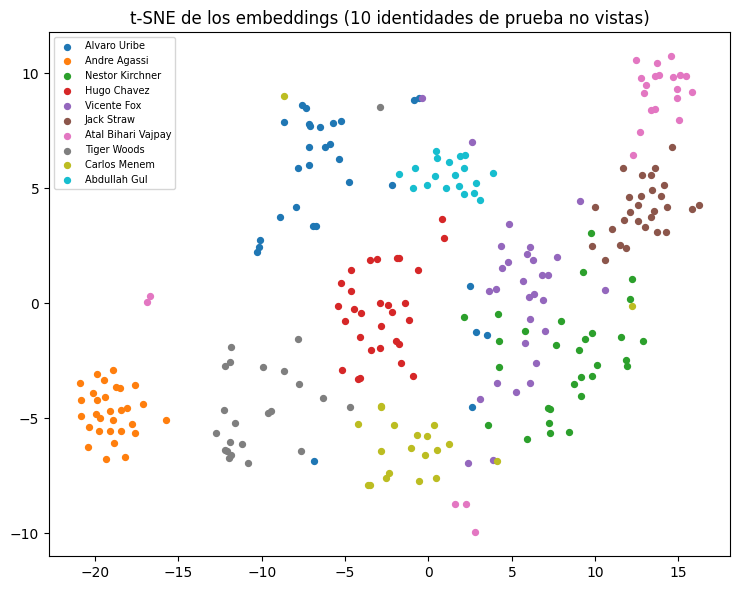

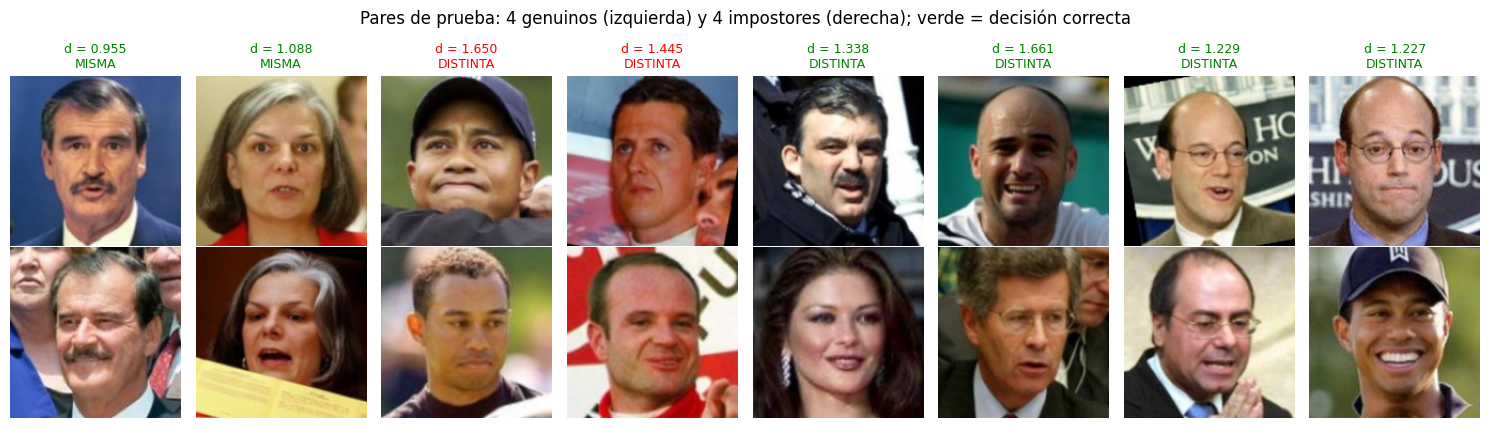

In [12]:
# ============================================================
# 7b. Espacio de embeddings (t-SNE) y ejemplos de pares
# ============================================================
from sklearn.manifold import TSNE
top = pd.Series(y_te).value_counts().index[:10]
m = np.isin(y_te, top)
Z = TSNE(n_components=2, perplexity=min(30, m.sum() - 1), init="pca", random_state=CONFIG["SEMILLA"]).fit_transform(E_te[m])
plt.figure(figsize=(7.5, 6))
for c in top:
    s = y_te[m] == c
    plt.scatter(Z[s, 0], Z[s, 1], s=18, label=nombres_lfw[c].replace("_", " ")[:18])
plt.legend(fontsize=7, loc="best"); plt.title("t-SNE de los embeddings (10 identidades de prueba no vistas)")
plt.tight_layout(); plt.savefig(f"{RES}/02_tsne_embeddings.png", dpi=130); plt.show()

g = np.random.default_rng(7)
sel = np.r_[g.choice(np.flatnonzero(lab_te == 1), 4, replace=False), g.choice(np.flatnonzero(lab_te == 0), 4, replace=False)]
fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for j, k in enumerate(sel):
    i1, i2 = pares_te[k]
    decision = "MISMA" if d_te[k] < umbral else "DISTINTA"
    correcto = (d_te[k] < umbral) == bool(lab_te[k])
    axes[0, j].imshow(X_te[i1]); axes[1, j].imshow(X_te[i2])
    axes[0, j].set_title(f"d = {d_te[k]:.3f}\n{decision}", fontsize=9, color="green" if correcto else "red")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Pares de prueba: 4 genuinos (izquierda) y 4 impostores (derecha); verde = decisión correcta")
plt.tight_layout(); plt.savefig(f"{RES}/02_ejemplos_pares.png", dpi=120); plt.show()

In [13]:
# ============================================================
# 8. Guardado del modelo, el umbral y las métricas
# ============================================================
codificador.save(os.path.join(MODELOS, "codificador_facial.keras"))
metadatos = {"umbral": umbral, "tam": TAM, "cache_lfw": NOMBRE_CACHE, "dim_emb": CONFIG["DIM_EMB"], "margen": CONFIG["MARGEN_TRIPLETE"],
             "ids_prueba": [int(i) for i in ids_te], "semilla": CONFIG["SEMILLA"]}
with open(os.path.join(MODELOS, "metadatos.json"), "w") as f:
    json.dump(metadatos, f, indent=2)
resultado = {
    "framework": f"TensorFlow {tf.__version__} / Keras {keras.__version__}",
    "gpu": [d.name for d in tf.config.list_physical_devices("GPU")],
    "lfw": {"imagenes": int(len(X_lfw)), "identidades": len(nombres_lfw), "sin_deteccion": n_alternativo,
            "division": division.to_dict(orient="records")},
    "parametros": {"total": int(codificador.count_params()),
                   "entrenables_fase2": int(sum(np.prod(v.shape) for v in codificador.trainable_weights))},
    "config": CONFIG, "epocas_entrenadas": len(historial["loss"]), "tiempo_min": tiempo_entrenamiento / 60,
    "historial": {k: [float(v) for v in vals] for k, vals in historial.items()},
    "umbral": umbral, "pares_prueba": int(len(pares_te)),
    "metricas_prueba": met, "metricas_linea_base": met_base,
}
with open(f"{RES}/02_metricas_siamesa.json", "w", encoding="utf-8") as f:
    json.dump(resultado, f, indent=2, ensure_ascii=False, default=str)
print("Guardado:", os.listdir(MODELOS))

Guardado: ['codificador_facial.keras', 'metadatos.json']
